# Notebook for optimising smFISH analysis parameters for formamide vs EC SNR comparison
## Revised: 2026.01.20

In [1]:
import os
import time

from skimage.morphology import white_tophat, black_tophat, disk
from scipy import ndimage, misc
import numpy as np
import tifffile
import matplotlib.pyplot as plt
import pathlib
from PIL import Image
import pandas as pd

import bigfish
import bigfish.stack as stack
import bigfish.multistack as multistack 
import bigfish.segmentation as segmentation
import bigfish.plot as plot
import bigfish.detection as detection

print("Big-FISH version: {0}".format(bigfish.__version__))

Big-FISH version: 0.6.2


/Users/jefflee/micromamba/envs/bigfish_v6/lib/python3.9/site-packages/bigfish/segmentation/nuc_segmentation.py:16: FutureWarning: The `skimage.morphology.selem` module is deprecated and will be removed in scikit-image 1.0 (`skimage.morphology.selem` has been moved to `skimage.morphology.footprints`).
  from skimage.morphology.selem import disk


# 0. Load Bigfish helper functions

In [2]:
## Calculate PSF (thanks MK!!)
def calculate_psf(voxel_size_z, voxel_size_yx, Ex, Em, NA, RI, microscope):
    if microscope == 'widefield':
        psf_yx = 0.225*Em/NA
        psf_z = 0.78*RI*Em/(NA**2)
    elif microscope in {'confocal', 'nipkow'}:
        psf_yx = 0.225/NA*Ex*Em/np.sqrt(Ex**2 + Em**2)
        psf_z = 0.78*RI/NA**2*Ex*Em/np.sqrt(Ex**2 + Em**2)
    else:
        print(f'microscope={microscope} is not a valid option')
        sys.exit()
    return psf_z, psf_yx

## Subtract background
def subtract_background(image, radius=5, light_bg=False):
    str_el = disk(radius) #you can also use 'ball' here to get a slightly smoother result at the cost of increased computing time
    if light_bg:
        return black_tophat(image, str_el)
    else:
        return white_tophat(image, str_el)

# 1. Import image and its metadata

In [16]:
# Import image file
file_name = "/Users/jefflee/Desktop/20251215_formamide_ethylenecarbonate_test/20251215_L3Brain_groupD_DAPI__chimo-exon_ago1-exon_60x_0002.tiff"
img = tifffile.imread(file_name)

print("Image imported: ", file_name)
print("\r shape: {0}".format(img.shape))
print("\r dtype: {0}".format(img.dtype))

# Set up image acquisition parameters
chan = 1
voxel_size_z = 200
voxel_size_yx = 65
Ex = 570
Em = 610
NA = 1.45
RI = 1.45
microscope = 'confocal'

psf_z = calculate_psf(voxel_size_z, voxel_size_yx, Ex, Em, NA, RI, microscope)[0]
psf_yx = calculate_psf(voxel_size_z, voxel_size_yx, Ex, Em, NA, RI, microscope)[1]

spot_radius_px = detection.get_object_radius_pixel(
    voxel_size_nm=(voxel_size_z, voxel_size_yx, voxel_size_yx), 
    object_radius_nm=(psf_z, psf_yx, psf_yx), 
    ndim = 3)

print(" ")
print("PSF and Sigma calculation finished")
print("\r theoretical psf_z = ", psf_z)
print("\r theoretical psf_yx = ", psf_yx)
print("\r spot radius (sigma_z) (z axis): {:0.3f} pixels".format(spot_radius_px[0]))
print("\r spot radius (sigma_yx) (yx plan): {:0.3f} pixels".format(spot_radius_px[-1]))

Image imported:  /Users/jefflee/Desktop/20251215_formamide_ethylenecarbonate_test/20251215_L3Brain_groupD_DAPI__chimo-exon_ago1-exon_60x_0002.tiff
 shape: (25, 3, 2000, 2000)
 dtype: uint16
 
PSF and Sigma calculation finished
 theoretical psf_z =  224.03449989716577
 theoretical psf_yx =  64.62533650879783
 spot radius (sigma_z) (z axis): 1.120 pixels
 spot radius (sigma_yx) (yx plan): 0.994 pixels


# 2. Optimise bigfish parameters
## 2-1. Get LoG filtred RNA channel image for pre-detection thresholding

In [17]:
# Background subtract RNA image and LoG filter
start_time = time.time()

# Channel subset original image
rna = np.swapaxes(img,0,1)[chan]

print("Image shape ")
print("\r shape: {0}".format(rna.shape))
print("\r dtype: {0}".format(rna.dtype))

# MIP image for plotting later or for 2D detection
rna_mip = stack.maximum_projection(rna)

# Background subtract
rna_no_bg = []
for z in rna:
    z_no_bg = subtract_background(z)
    rna_no_bg.append(z_no_bg)
rna = np.array(rna_no_bg)

print ("Background subtraction finished ", time.time() - start_time, "sec")

# LoG filter
rna_log = stack.log_filter(rna, sigma = spot_radius_px)
print ("LoG filter finished ", time.time() - start_time, "sec")

# Export LoG filtered image to the working directory
rna_log_max = np.max(rna_log, 0)
Image.fromarray(rna_log_max).save('rna_log.tif')

print ("Image saved to working dir! Open it on ImageJ! ", time.time() - start_time, "sec")


Image shape 
 shape: (25, 2000, 2000)
 dtype: uint16
Background subtraction finished  22.6679208278656 sec
LoG filter finished  27.6991868019104 sec
Image saved to working dir! Open it on ImageJ!  27.75801992416382 sec


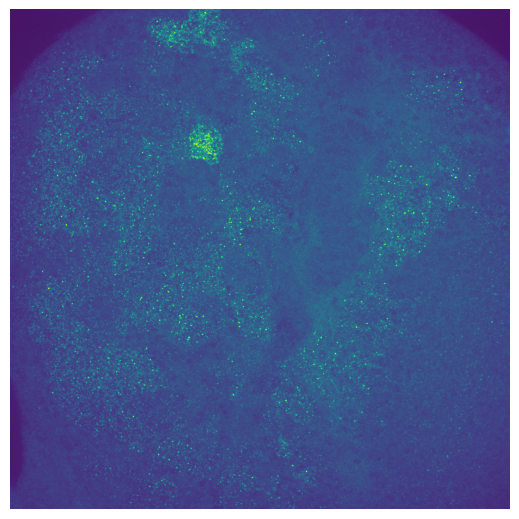

In [18]:
plot.plot_images(rna_mip, framesize = (5, 5), contrast=True)

## 2-2 Optimise single-spot detection

### Option 1 - Manual thresholding

pre-detection done
threshold done 8.208769083023071 sec
detected spots
 shape: (2398, 3)
 dtype: int64
 threshold: 8


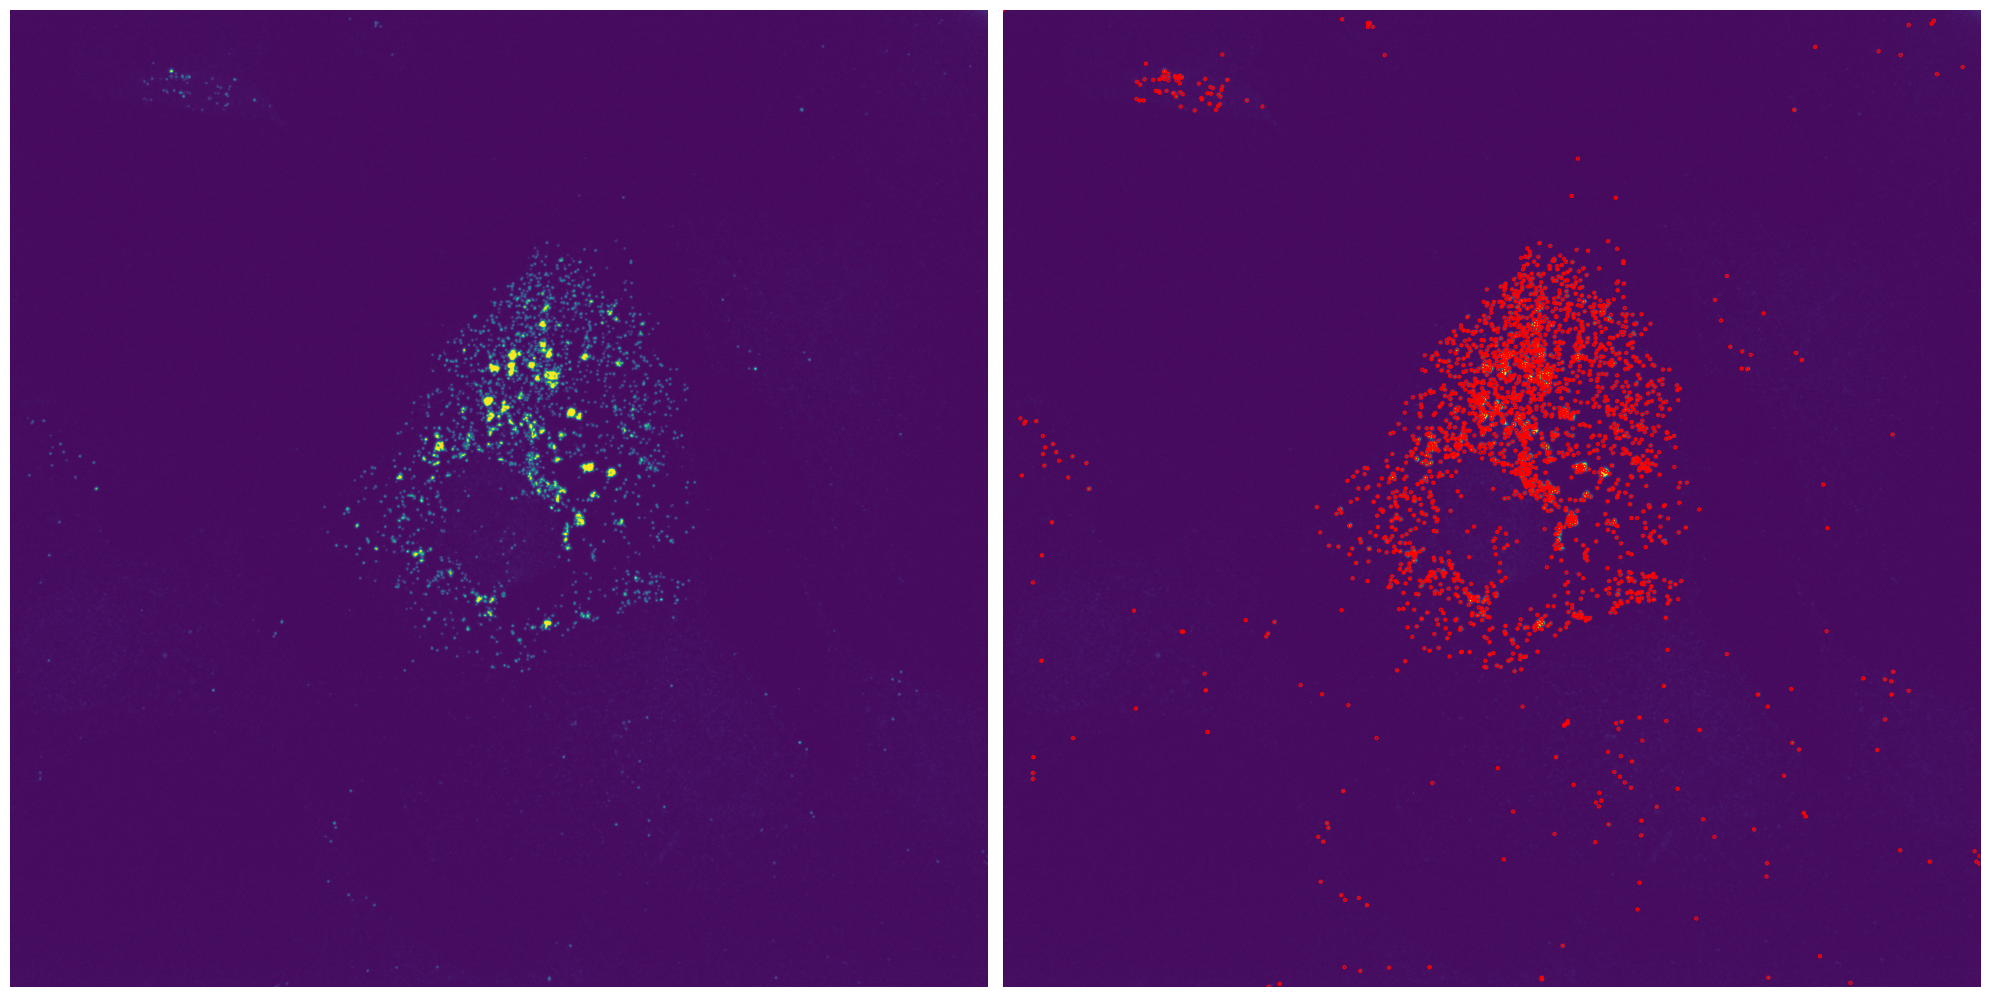

Plotting done  14.669450044631958 sec


In [75]:
start_time = time.time()

## local maximum detection
mask = detection.local_maximum_detection(rna_log, min_distance = spot_radius_px)
print ('pre-detection done')

## thresholding
threshold = 8
spots, _ = detection.spots_thresholding(rna_log, mask, threshold)
print ('threshold done', time.time() - start_time, "sec")

print("detected spots")
print("\r shape: {0}".format(spots.shape))
print("\r dtype: {0}".format(spots.dtype))
print("\r threshold: {0}".format(threshold))

## Plot detected spots
plot.plot_detection(rna_mip, spots, radius = 3, framesize = (20, 16), contrast = True)
print ("Plotting done ", time.time() - start_time, "sec")


In [76]:
# z, y, x
print(spots.shape)
print(spots[:5])

(2398, 3)
[[   2    0    0]
 [   2 1258  710]
 [   4  759  965]
 [   4  936  146]
 [   4  955   87]]


### Option 2 - Auto-thresholding

In [21]:
def plot_elbow_value(
        images,
        voxel_size=None,
        spot_radius=None,
        log_kernel_size=None,
        minimum_distance=None,
        title=None,
        framesize=(5, 5),
        size_title=20,
        size_axes=15,
        size_legend=15,
        path_output=None,
        ext="png",
        show=True):
    """Plot the elbow curve that allows an automated spot detection.

    Parameters
    ----------
    images : list
        List of ndarrays with shape (z, y, x) or (y, x). The same threshold is
        applied to every images.
    voxel_size : int or float or tuple or list, optional
        Size of a voxel, in nanometer. One value per spatial dimension (zyx or
        yx dimensions). If it's a scalar, the same value is applied to every
        dimensions. Not used if 'log_kernel_size' and 'minimum_distance' are
        provided.
    spot_radius : int or float or tuple or list, optional
        Radius of the spot, in nanometer. One value per spatial dimension (zyx
        or yx dimensions). If it's a scalar, the same radius is applied to
        every dimensions. Not used if 'log_kernel_size' and 'minimum_distance'
        are provided.
    log_kernel_size : int or float or tuple or list, optional
        Size of the LoG kernel. It equals the standard deviation (in pixels)
        used for the gaussian kernel (one for each dimension). One value per
        spatial dimension (zyx or yx dimensions). If it's a scalar, the same
        standard deviation is applied to every dimensions. If None, we estimate
        it with the voxel size and spot radius.
    minimum_distance : int or float or tuple or list, optional
        Minimum distance (in pixels) between two spots we want to be able to
        detect separately. One value per spatial dimension (zyx or yx
        dimensions). If it's a scalar, the same distance is applied to every
        dimensions. If None, we estimate it with the voxel size and spot
        radius.
    title : str, optional
        Title of the plot.
    framesize : tuple, default=(5, 5)
        Size of the frame used to plot with ``plt.figure(figsize=framesize)``.
    size_title : int, default=20
        Size of the title.
    size_axes : int, default=15
        Size of the axes label.
    size_legend : int, default=15
        Size of the legend.
    path_output : str, optional
        Path to save the image (without extension).
    ext : str or list, default='png'
        Extension used to save the plot. If it is a list of strings, the plot
        will be saved several times.
    show : bool, default=True
        Show the figure or not.

    """
    # check parameters
    stack.check_parameter(
        title=(str, list, type(None)),
        framesize=tuple,
        size_title=int,
        size_axes=int,
        size_legend=int,
        path_output=(str, type(None)),
        ext=(str, list),
        show=bool)

    # get candidate thresholds and spots count to plot the elbow curve
    thresholds, count_spots, threshold = detection.get_elbow_values(
        images,
        voxel_size=voxel_size,
        spot_radius=spot_radius,
        log_kernel_size=log_kernel_size,
        minimum_distance=minimum_distance)

    # plot
    plt.figure(figsize=framesize)
    plt.plot(thresholds, count_spots, c="#2c7bb6", lw=2)
    if threshold is not None:
        i_threshold = np.argmax(thresholds == threshold)
        plt.scatter(
            threshold,
            count_spots[i_threshold],
            marker="D",
            c="#d7191c",
            s=60,
            label=f"Selected threshold: {threshold:.2f}")  # MODIFIED: Added threshold value

    # axes
    if title is not None:
        plt.title(title, fontweight="bold", fontsize=size_title)
    plt.xlabel("Thresholds", fontweight="bold", fontsize=size_axes)
    plt.ylabel(
        "Number of mRNAs detected (log scale)",
        fontweight="bold",
        fontsize=size_axes)
    if threshold is not None:
        plt.legend(prop={'size': size_legend})
    plt.tight_layout()
    if path_output is not None:
        save_plot(path_output, ext)
    if show:
        plt.show()
    else:
        plt.close()

pre-detection done


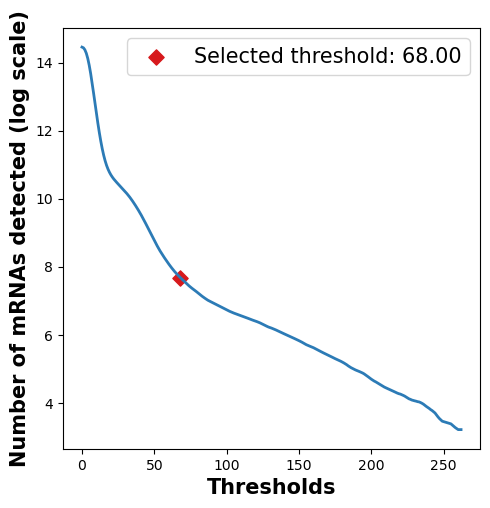

Elbow plot done  17.773913860321045 sec
Auto-threshold value found 18.619528770446777 sec
 threshold: 68.0
threshold done 19.68275475502014 sec
detected spots
 shape: (2070, 3)
 dtype: int64
 threshold: 68.0


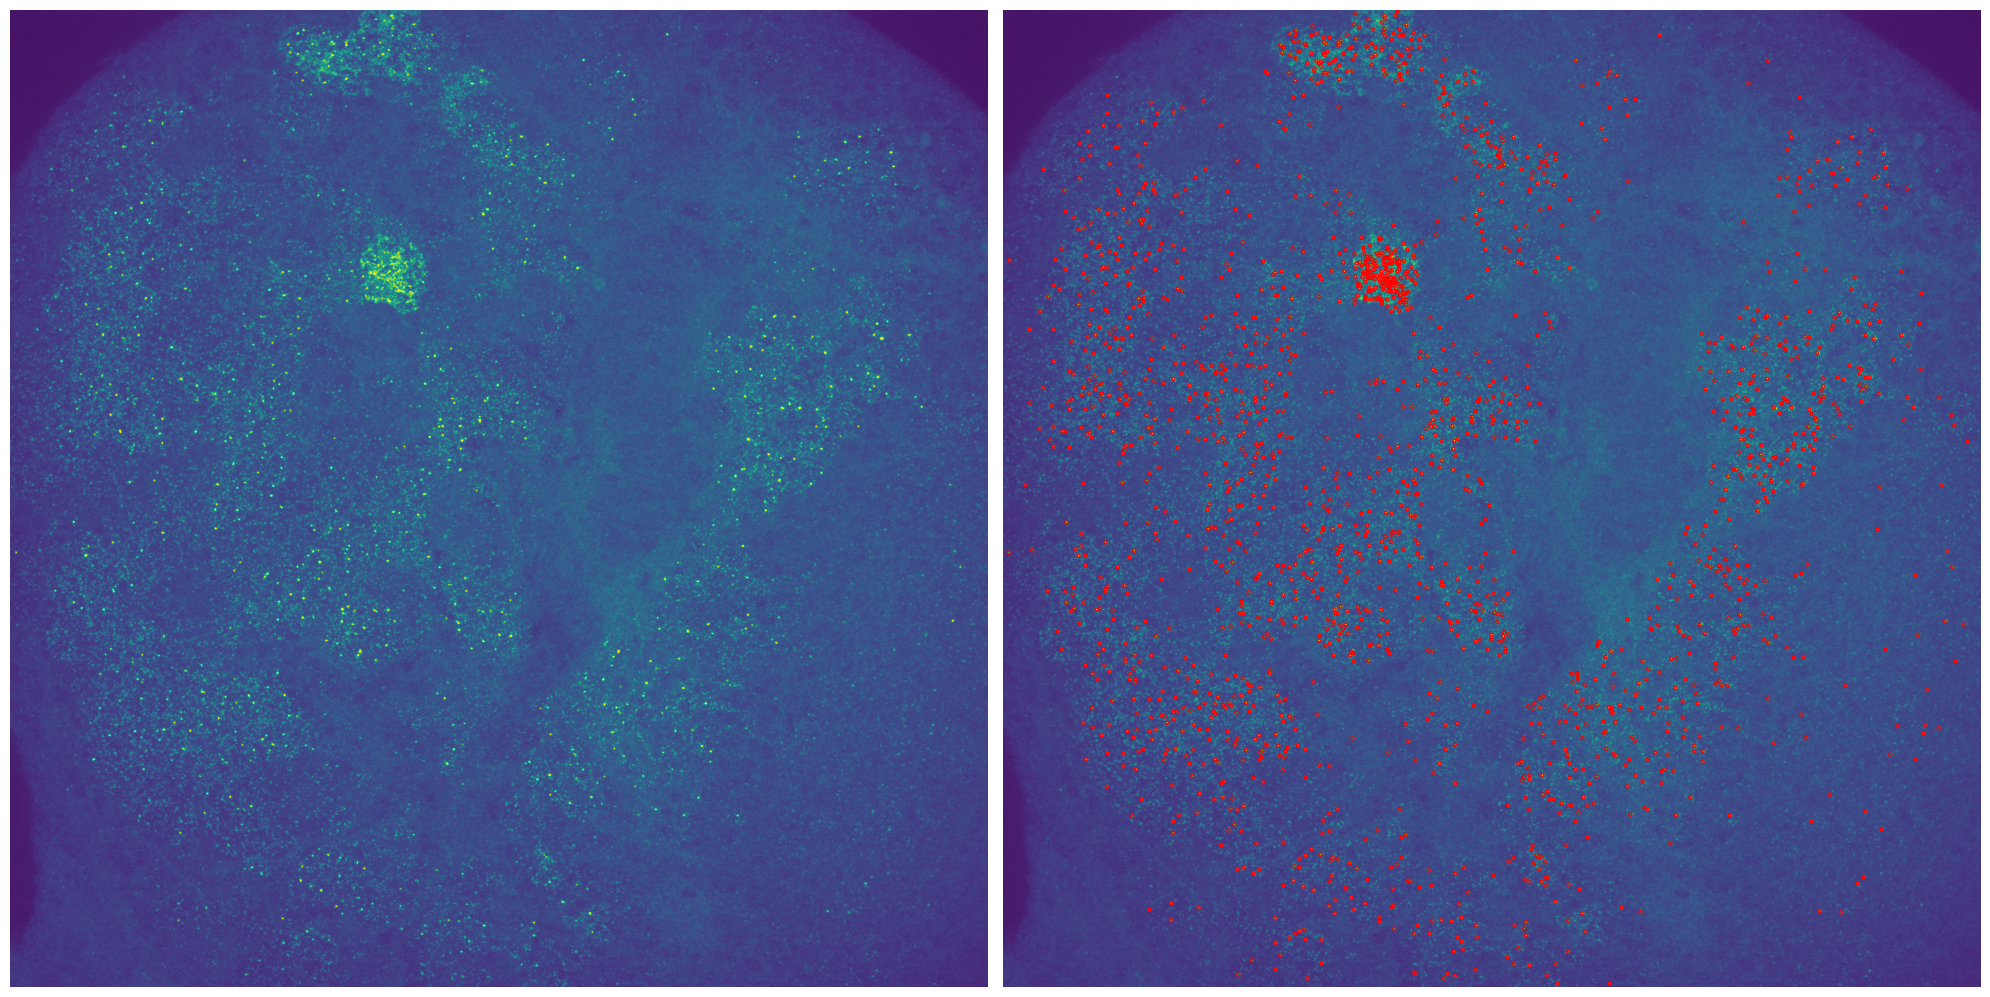

Plotting done  23.188227653503418 sec


In [23]:
start_time = time.time()

## local maximum detection
mask = detection.local_maximum_detection(rna_log, min_distance = spot_radius_px)
print ('pre-detection done')

## Get Elbow plot
plot_elbow_value(
    rna,
    voxel_size = (voxel_size_z, voxel_size_yx, voxel_size_yx),
    spot_radius = (psf_z, psf_yx, psf_yx)
)
print ("Elbow plot done ", time.time() - start_time, "sec")

## Get autothreshold value
threshold_auto = detection.automated_threshold_setting(rna_log, mask)
print("Auto-threshold value found", time.time() - start_time, "sec")
print("\r threshold: {0}".format(threshold_auto))

## thresholding (automated)
spots, _ = detection.spots_thresholding(rna_log, mask, threshold_auto)
print ('threshold done', time.time() - start_time, "sec")

print("detected spots")
print("\r shape: {0}".format(spots.shape))
print("\r dtype: {0}".format(spots.dtype))
print("\r threshold: {0}".format(threshold_auto))

## Plot detected spots
plot.plot_detection(rna_mip, spots, radius = 3, framesize = (20, 16), contrast = True)
print ("Plotting done ", time.time() - start_time, "sec")

## 2-3. Quantify dense regions

### 2-3-1. Get a reference spot

Denoising done  6.341676950454712 sec
Denoised reference spot for decompose cluster 6.355360746383667 sec
 shape: (5, 5, 5)
 dtype: uint16


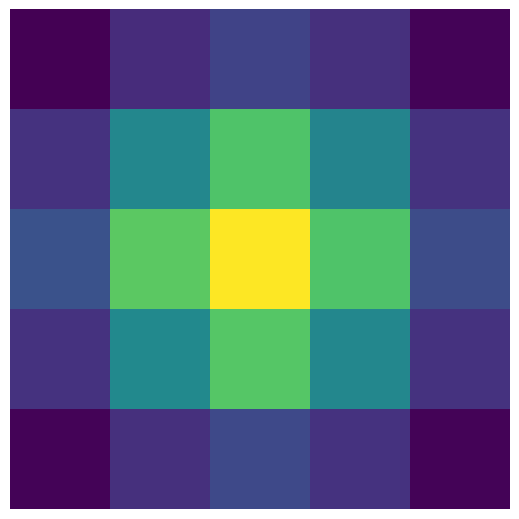

In [7]:
start_time = time.time() 

## gaussian kernel
kernel_size = detection.get_object_radius_pixel(
    voxel_size_nm = (voxel_size_z, voxel_size_yx, voxel_size_yx),
    object_radius_nm = (psf_z, psf_yx, psf_yx),
    ndim = 3
)
large_kernel_size = tuple([kernel_size_ * 5 for kernel_size_ in kernel_size])

# denoising
rna_denoised = stack.remove_background_gaussian(rna, sigma = large_kernel_size)
print("Denoising done ", time.time() - start_time, "sec")

# reference spot from denoised 
reference_spot = detection.build_reference_spot(
    image = rna_denoised,
    spots = spots,
    voxel_size = (voxel_size_z, voxel_size_yx, voxel_size_yx),
    spot_radius = (psf_z, psf_yx, psf_yx),
    alpha = 0.5
)

print("Denoised reference spot for decompose cluster", time.time() - start_time, "sec")
print("\r shape: {0}".format(reference_spot.shape))
print("\r dtype: {0}".format(reference_spot.dtype))

plot.plot_reference_spot(reference_spot, rescale = True)


### 2-3-2. Decompose dense regions with the reference spot

fitted gaussian to ref spot 0.011533021926879883 sec
detected potential dense regions 13.182646036148071 sec
 my cluster region counts are:  27047
pre-computed gaussian 13.18818211555481 sec
gaussian mixture simulation done 15.726180076599121 sec 

detected spots before decomposition
 shape: (60584, 3)
 dtype: int64 

detected spots after decomposition
 shape: (83001, 3)
 dtype: int64


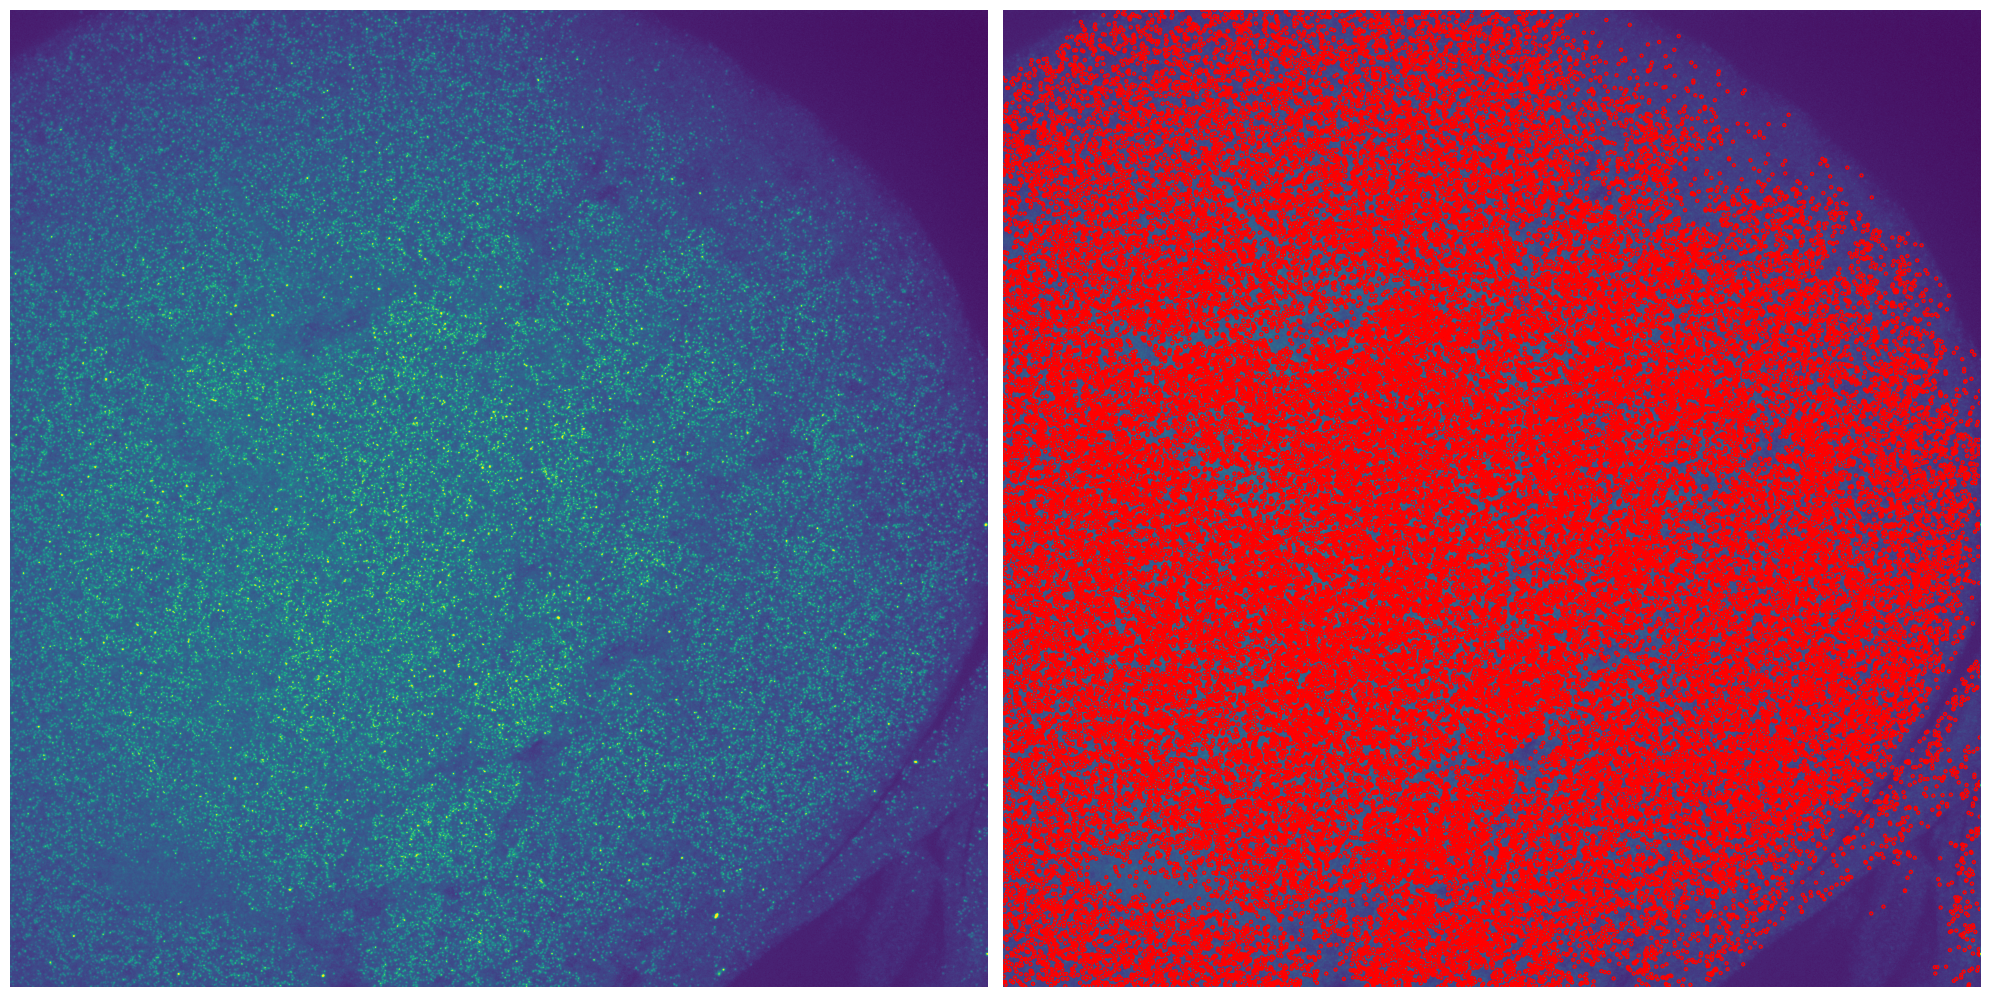

Plotting done  115.08073592185974 sec


In [8]:
start_time = time.time() 

# fit a gaussian function on the reference spot
sigma_z, sigma_yx, amplitude, background = detection.modelize_spot(
    reference_spot = reference_spot, 
    voxel_size = (voxel_size_z, voxel_size_yx, voxel_size_yx),
    spot_radius = (psf_z, psf_yx, psf_yx)
)
    
print ('fitted gaussian to ref spot', time.time() - start_time, "sec")

# detect potential dense regions
regions_to_decompose, spots_out_regions, region_size = detection.get_dense_region(
    image = rna_denoised, 
    spots = spots,
    voxel_size = (voxel_size_z, voxel_size_yx, voxel_size_yx),
    spot_radius = (psf_z, psf_yx, psf_yx),
    beta = 1
)
    
print('detected potential dense regions', time.time() - start_time, "sec")
print("\r my cluster region counts are: ", len(regions_to_decompose))

# precompute gaussian function values
max_grid = max(200, region_size + 1)
precomputed_gaussian = detection.precompute_erf(
    ndim = 3,
    voxel_size = (voxel_size_z, voxel_size_yx, voxel_size_yx),
    sigma = (sigma_z, sigma_yx, sigma_yx),
    max_grid = max_grid
)

print ('pre-computed gaussian', time.time() - start_time, "sec")

# simulate gaussian mixtures
spots_in_regions, _ = detection.simulate_gaussian_mixture(
    image = rna_denoised,
    candidate_regions = regions_to_decompose,
    voxel_size = (voxel_size_z, voxel_size_yx, voxel_size_yx),
    sigma = (sigma_z, sigma_yx, sigma_yx),
    amplitude = amplitude,
    background = background,
    precomputed_gaussian = precomputed_gaussian)

spots_post_decomposition = np.concatenate((spots_out_regions, spots_in_regions[:, :3]), axis=0)

print ('gaussian mixture simulation done', time.time() - start_time, "sec", "\n")

print("detected spots before decomposition")
print("\r shape: {0}".format(spots.shape))
print("\r dtype: {0}".format(spots.dtype), "\n")
print("detected spots after decomposition")
print("\r shape: {0}".format(spots_post_decomposition.shape))
print("\r dtype: {0}".format(spots_post_decomposition.dtype))

plot.plot_detection(rna_mip, spots_post_decomposition, framesize = (20, 16), contrast = True)
print ("Plotting done ", time.time() - start_time, "sec")

In [10]:
def compute_snr_spots_individual(
    image,
    spots,
    voxel_size,
    spot_radius
):
    """
    Compute SNR for each individual spot.
    
    Parameters
    ----------
    image : np.ndarray
        Image with shape (z, y, x).
    spots : np.ndarray
        Coordinates of spots with shape (nb_spots, 3) for zyx coordinates.
    voxel_size : tuple
        Voxel size in nanometers (voxel_size_z, voxel_size_yx, voxel_size_yx).
    spot_radius : tuple
        Theoretical spot radius in nanometers (radius_z, radius_yx, radius_yx).
    
    Returns
    -------
    snr_values : np.ndarray
        Array of SNR values for each spot with shape (nb_spots,).
    """
    import numpy as np
    from bigfish.detection import get_object_radius_pixel
    
    # Convert spot radius from nm to pixels
    spot_radius_px = get_object_radius_pixel(
        voxel_size_nm=voxel_size,
        object_radius_nm=spot_radius,
        ndim=3
    )
    
    # Define the region sizes for signal and background
    signal_radius = tuple([int(np.ceil(r)) for r in spot_radius_px])
    background_inner_radius = tuple([int(np.ceil(r * 1.5)) for r in spot_radius_px])
    background_outer_radius = tuple([int(np.ceil(r * 2.5)) for r in spot_radius_px])
    
    snr_values = []
    
    for spot_coord in spots:
        z, y, x = int(spot_coord[0]), int(spot_coord[1]), int(spot_coord[2])
        
        # Define bounds for extraction (with boundary checks)
        z_min = max(0, z - background_outer_radius[0])
        z_max = min(image.shape[0], z + background_outer_radius[0] + 1)
        y_min = max(0, y - background_outer_radius[1])
        y_max = min(image.shape[1], y + background_outer_radius[1] + 1)
        x_min = max(0, x - background_outer_radius[2])
        x_max = min(image.shape[2], x + background_outer_radius[2] + 1)
        
        # Extract local region
        local_region = image[z_min:z_max, y_min:y_max, x_min:x_max]
        
        # Create coordinate grids relative to spot center
        zz, yy, xx = np.ogrid[
            z_min-z:z_max-z,
            y_min-y:y_max-y,
            x_min-x:x_max-x
        ]
        
        # Calculate distances (accounting for anisotropic voxels)
        distances = np.sqrt(
            (zz / spot_radius_px[0])**2 + 
            (yy / spot_radius_px[1])**2 + 
            (xx / spot_radius_px[2])**2
        )
        
        # Create masks for signal and background regions
        signal_mask = distances <= 1.0
        background_mask = (distances > 1.5) & (distances <= 2.5)
        
        # Calculate signal and background
        if np.sum(signal_mask) > 0 and np.sum(background_mask) > 0:
            signal = np.mean(local_region[signal_mask])
            background = np.mean(local_region[background_mask])
            background_std = np.std(local_region[background_mask])
            
            # Calculate SNR
            if background_std > 0:
                snr = (signal - background) / background_std
            else:
                snr = 0
        else:
            snr = 0
        
        snr_values.append(snr)
    
    return np.array(snr_values)

In [11]:
# Calculate individual SNR values for each spot
snr_values = compute_snr_spots_individual(
    image=rna,  # or rna_denoised, depending on what you want
    spots=spots_post_decomposition,
    voxel_size=(voxel_size_z, voxel_size_yx, voxel_size_yx),
    spot_radius=(psf_z, psf_yx, psf_yx)
)

# Now snr_values is an array where each element corresponds to each spot
print(f"Number of spots: {len(spots_post_decomposition)}")
print(f"Number of SNR values: {len(snr_values)}")
print(f"Mean SNR: {np.mean(snr_values):.2f}")
print(f"Median SNR: {np.median(snr_values):.2f}")



Number of spots: 83001
Number of SNR values: 83001
Mean SNR: 2.31
Median SNR: 2.26


In [ ]:
# You can add SNR as a 4th column to your spots array
spots_with_snr = np.column_stack([spots_post_decomposition, snr_values])
print(spots_with_snr[:5])  # Show first 5 spots with their SNR values